# Lecture 14: K-means clustering

- **Cluster:** group images using similarity in their feature representations.
- **Represent:** compare flattened pixels with pretrained image features.
- **Inspect:** examine cluster members and consider the choice of number of clusters.

**Predict:** Will images that look similar to us always be close in pixel space?

## Setup and imports

- Run cells in order using this directory's `.venv`, with `content/classes/varada` as the working directory.
- Dependencies: PyTorch, torchvision, scikit-learn, NumPy, pandas, and Matplotlib (included in this directory's project environment).
- Place the small bird and food image subsets in `data/birds/` and `data/food/`. Each folder must contain one subfolder per image category, as required by `ImageFolder`.
- Dataset sources: [200 Bird Species](https://www.kaggle.com/datasets/veeralakrishna/200-bird-species-with-11788-images) and [Food-101](https://www.kaggle.com/datasets/kmader/food41).
- The first feature-extraction run may download pretrained DenseNet weights and needs internet access.
- Use small subsets: this demo loads each image dataset into memory.

In [2]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.cluster import KMeans
from torchvision import datasets, models, transforms

%matplotlib inline
DATA_DIR = Path("data")
IMAGE_SIZE = 224
RANDOM_STATE = 123
plt.rcParams.update({"figure.figsize": (8, 4)})

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

for name in ["birds", "food"]:
    data_path = DATA_DIR / name
    if not data_path.is_dir():
        raise FileNotFoundError(
            f"Place the {name} image subset in {data_path.resolve()}, "
            "with one subfolder per category. Run from content/classes/varada."
        )

## 1. Inspect the bird images

- Each image becomes a tensor with shape `(channels, height, width)`.
- Load images in a fixed order so pixels, pretrained features, and displayed images refer to the same rows.
- Category labels come with the dataset; K-means will use only the image representations.

In [3]:
def read_img_dataset(data_dir):
    """Load a small ImageFolder dataset as resized RGB tensors in [0, 1]."""
    image_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
    ])
    image_dataset = datasets.ImageFolder(data_dir, transform=image_transform)
    loader = torch.utils.data.DataLoader(
        image_dataset, batch_size=min(32, len(image_dataset)),
        shuffle=False, num_workers=0,
    )
    batches = list(loader)
    inputs = torch.cat([images for images, _ in batches])
    labels = torch.cat([labels for _, labels in batches])
    return inputs, labels, image_dataset.classes


def plot_sample_imgs(inputs, n_img=24, title="Sample images"):
    """Display RGB tensors without changing their row order."""
    n_img = min(n_img, len(inputs))
    n_cols = min(6, n_img)
    n_rows = (n_img + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image in zip(axes.flat, inputs[:n_img]):
        ax.imshow(image.permute(1, 2, 0).numpy())
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def get_cluster_images(model, inputs, cluster, n_img=6):
    """Display the first members of one cluster using matching feature/image rows."""
    indices = np.flatnonzero(model.labels_ == cluster)[:n_img]
    if len(indices) == 0:
        print(f"Cluster {cluster} has no images.")
        return
    plot_sample_imgs(inputs[indices], n_img=n_img, title=f"Cluster {cluster}")

176 images; source categories: ['017.Cardinal', '020.Yellow_breasted_Chat', '054.Blue_Grosbeak']
Image tensor shape: (176, 3, 224, 224)


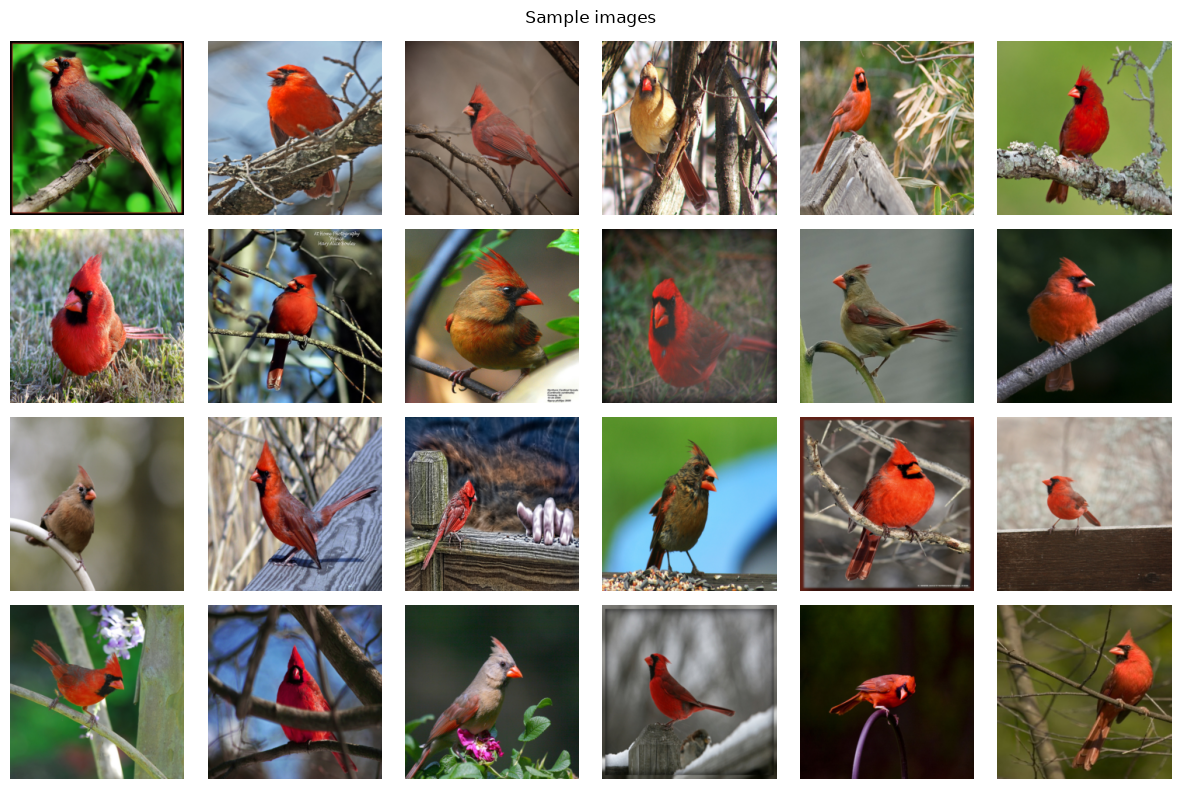

In [5]:
birds_inputs, birds_labels, bird_categories = read_img_dataset(DATA_DIR / "birds")
print(f"{len(birds_inputs)} images; source categories: {bird_categories}")
print(f"Image tensor shape: {tuple(birds_inputs.shape)}")
plot_sample_imgs(birds_inputs)

## 2. K-means on flattened pixels

- Flatten each image into a vector of $3 \times 224 \times 224$ pixel values.
- K-means assigns each image to its nearest centre using Euclidean distance.
- Choose `k = 3` for this bird subset; category labels are not passed to the model.

**Predict:** Will these clusters reflect bird species, background colours, or both?

In [6]:
flatten_images = birds_inputs.flatten(start_dim=1).numpy()
flatten_images.shape

(176, 150528)

In [7]:
k = 3
km_flatten = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
km_flatten.fit(flatten_images)
km_flatten.cluster_centers_.shape

(3, 150528)

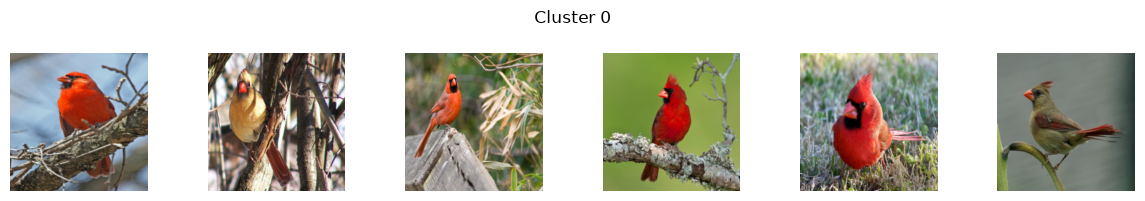

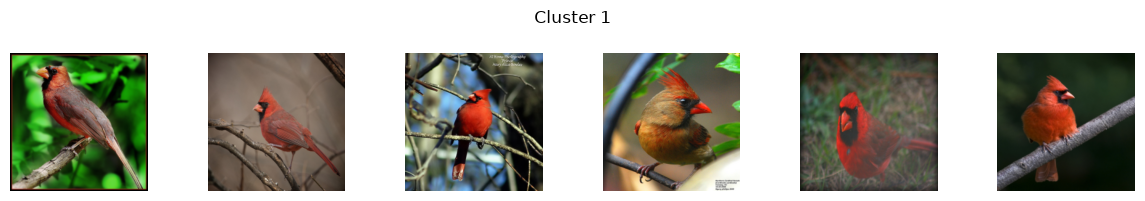

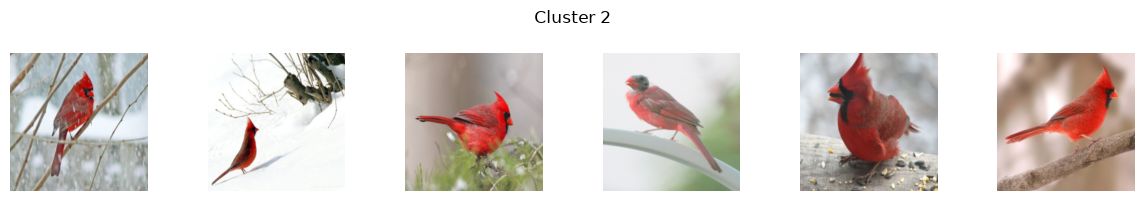

In [8]:
for cluster in range(k):
    get_cluster_images(km_flatten, birds_inputs, cluster)

### Inspect the pixel-space centres

- Each centre is the mean pixel vector of its assigned images.
- Reshape it back into an image to see what averaging pixels produces.
- Cluster numbers are arbitrary identifiers; they are not category labels.

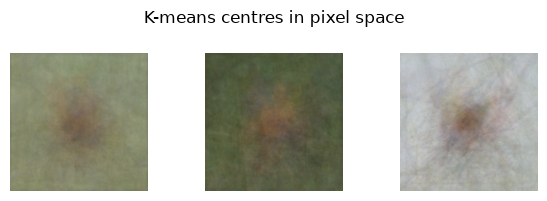

In [9]:
pixel_centres = torch.from_numpy(km_flatten.cluster_centers_).reshape(
    k, 3, IMAGE_SIZE, IMAGE_SIZE
)
plot_sample_imgs(pixel_centres, n_img=k, title="K-means centres in pixel space")

**Discuss:** Which visual properties seem to drive these groups? Why might pixel distance miss similarity in bird shape?

<details>
<summary>Reveal explanation</summary>

- Pixel distance compares values at matching image positions.
- Background, lighting, and the position of the bird can dominate this distance.
- Similar birds in different poses can be far apart in pixel space.
- A different representation changes what “nearby” means to K-means.

</details>

## 3. K-means on pretrained image features

- Use a pretrained DenseNet as a **feature extractor**; do not train a neural network here.
- Remove its classification layer to obtain one feature vector per image.
- Apply the preprocessing supplied with the pretrained weights.
- Keep the same bird images and `k = 3` to compare representations.

**Predict:** How might these features change which images are grouped together?

In [10]:
weights = models.DenseNet121_Weights.IMAGENET1K_V1
feature_transform = weights.transforms()
densenet = models.densenet121(weights=weights)
densenet.classifier = torch.nn.Identity()
densenet.eval();

In [11]:
def get_features(model, inputs, batch_size=16):
    """Extract pretrained features in small CPU batches, preserving image order."""
    model.eval()
    features = []
    with torch.inference_mode():
        for batch in inputs.split(batch_size):
            prepared = feature_transform(batch)
            features.append(model(prepared).cpu())
    return torch.cat(features).numpy()


Z_birds = get_features(densenet, birds_inputs)
pd.DataFrame(Z_birds).head()

,0,1,2,3,4,5,6,7,8,9,...,1014,1015,1016,1017,1018,1019,1020,1021,1022,1023
0,0.000197,0.006181,0.003704,0.001409,0.072644,0.428427,0.000230,0.003897,0.167407,0.000092,...,0.653268,0.566624,0.478301,0.021800,0.205303,0.367466,1.254782,1.249258,0.140211,0.329055
1,0.000165,0.002631,0.003767,0.003984,0.117051,0.241621,0.000793,0.003583,0.054932,0.000206,...,0.501949,0.595826,0.514817,0.271111,0.078196,0.203349,0.537986,1.045885,0.100572,0.643479
2,0.000092,0.002316,0.002552,0.002741,0.075190,1.090982,0.000761,0.004849,0.245861,0.000327,...,1.189215,0.098815,0.608837,1.053601,0.126286,0.144582,0.930413,0.262126,0.112451,0.900482
3,0.000110,0.005061,0.001524,0.001414,0.200663,0.717928,0.000498,0.002972,0.235944,0.000181,...,1.384396,0.108290,0.746991,0.707422,0.505277,1.152947,1.310641,0.140999,0.015184,0.789837
4,0.000186,0.002806,0.002480,0.002705,0.224436,0.456339,0.000677,0.003608,0.184346,0.000178,...,1.506947,0.400076,0.213738,0.420479,0.226221,0.061750,1.037683,0.834745,0.053219,0.524462


In [12]:
Z_birds.shape

(176, 1024)

In [13]:
km_birds = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
km_birds.fit(Z_birds)
km_birds.cluster_centers_.shape

(3, 1024)

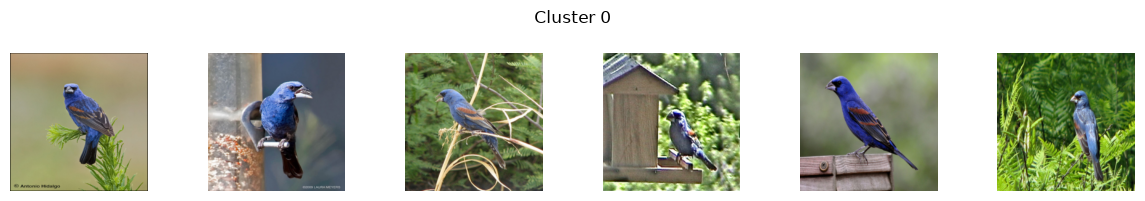

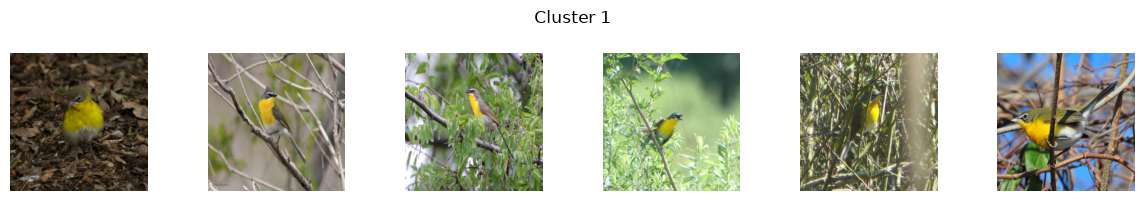

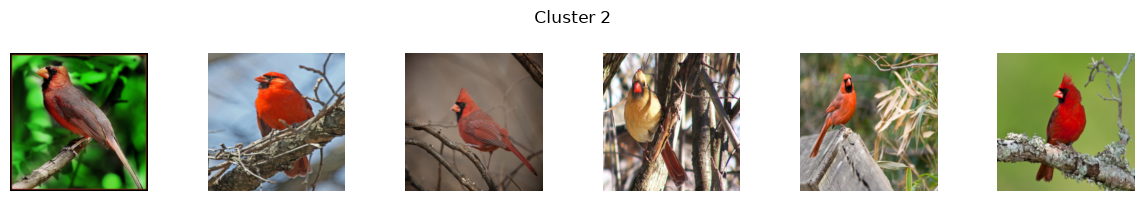

In [14]:
for cluster in range(k):
    get_cluster_images(km_birds, birds_inputs, cluster)

**Inspect:** Compare these groups with the pixel-based groups.

- Are birds with similar appearance grouped together more consistently?
- Which images still seem out of place?
- The centres now live in feature space; reshaping them into RGB images would not be meaningful.
- Judge the observed groups rather than assuming pretrained features always work better.

## 4. Try a more varied dataset: food images

- Extract features using the same pretrained model.
- Start with `k = 5` for this subset.
- Different views, backgrounds, and ingredients may make groups harder to separate.

**Predict:** Which kinds of food might end up in the same cluster?

350 images; source categories: ['beet_salad', 'chocolate_cake', 'edamame', 'french_fries', 'pizza', 'spring_rolls', 'sushi']


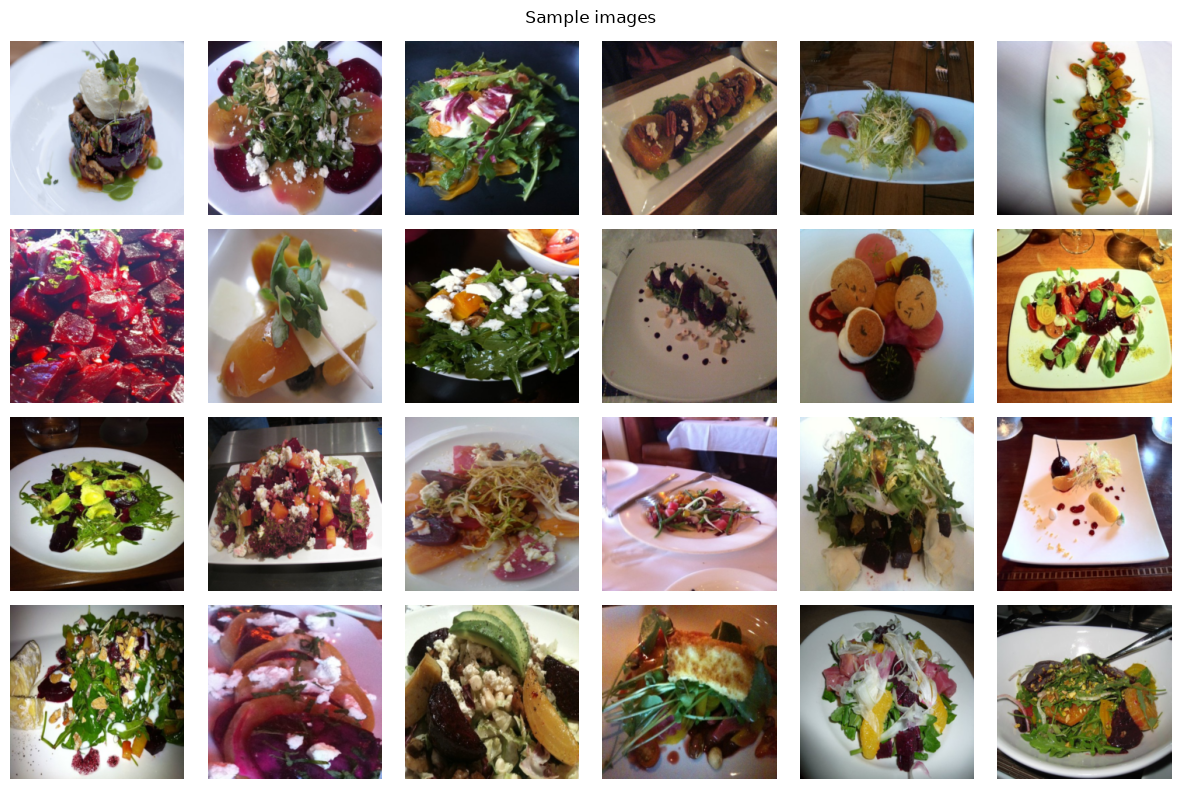

In [15]:
food_inputs, food_labels, food_categories = read_img_dataset(DATA_DIR / "food")
print(f"{len(food_inputs)} images; source categories: {food_categories}")
plot_sample_imgs(food_inputs)

In [16]:
Z_food = get_features(densenet, food_inputs)
Z_food.shape

(350, 1024)

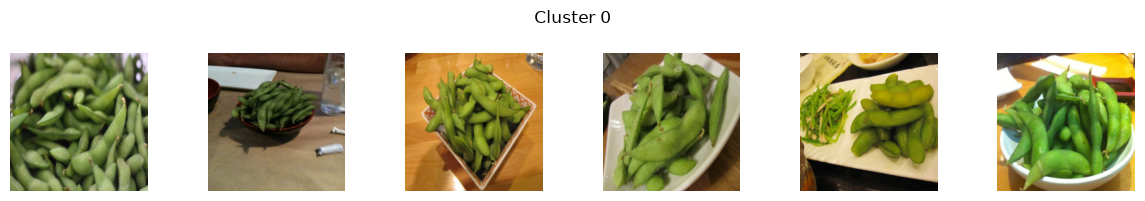

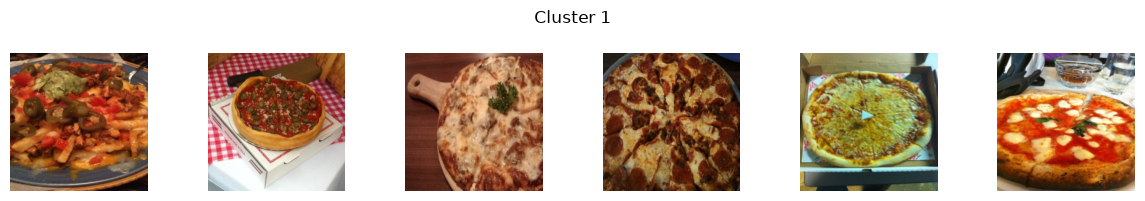

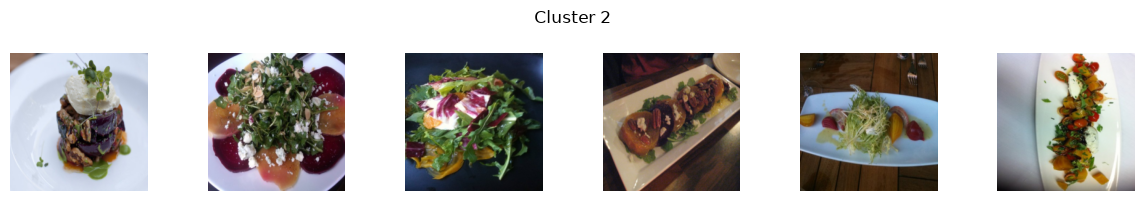

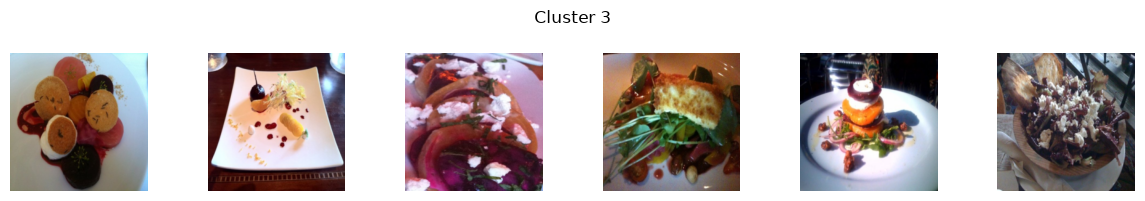

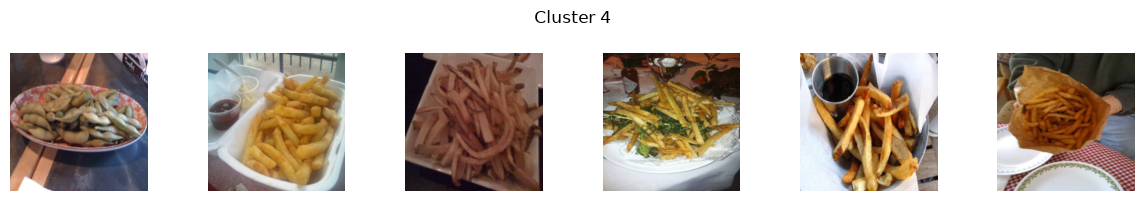

In [17]:
k_food = 5
km_food = KMeans(n_clusters=k_food, n_init=10, random_state=RANDOM_STATE)
km_food.fit(Z_food)

for cluster in range(k_food):
    get_cluster_images(km_food, food_inputs, cluster)

## 5. Check your interpretation

- What changed between the two bird clustering examples?
- Does a cluster ID tell us the image's food or bird category?
- What might happen if we increase or decrease `k`?
- Why should we inspect several images from each cluster?

<details>
<summary>Reveal answers</summary>

- The representation and its distances changed; the images and number of clusters stayed the same.
- No. Cluster IDs are arbitrary; clustering does not learn from the supplied category labels.
- A larger `k` splits images into more groups; a smaller `k` combines them into fewer groups. More groups do not automatically mean more useful groups.
- A few examples can hide variation within a cluster. Inspect more members before describing the whole group.

</details>

**Experiment:** Change `k_food`, rerun the food clustering, and compare the groups. Consider which distinctions are useful for your goal.